# 분류(2)

# 앙상블 학습

앙상블 학습(Ensemble Learning)을 통한 분
류는 여러 개의 분류기 (Classifier)를 생성하
고 그 예측을 결합함으로써 보다 정확한 최종
예측을 도출하는 기법이다.
- 목표: 단일 분류기 보다 신뢰성이 높은 예측값을 얻는 것

앙상블 유형 = 보팅(Voting), 배깅(Bagging), 부스팅(Boosting)
- 보팅과 배깅은 여러 개의 분류기가 투표를 통해 최종 예측 결과를 결정하는 방식
  - 보팅과 배징의 다른 점
    - 보팅의 경우 일반적으로 서로 다른 알고리즘을 가진 분류기를 결합하는 것
    - 배깅의 경우 각각의 분류기가 모두 같은 유형의 알고리즘 기반이지만, 데이터 샘플링을 서로 다르게 가져가면서 학습을 수행해 보팅을 수행하는 것 / 대표적인 배깅 방식 = 랜덤 포레스트 알고리즘

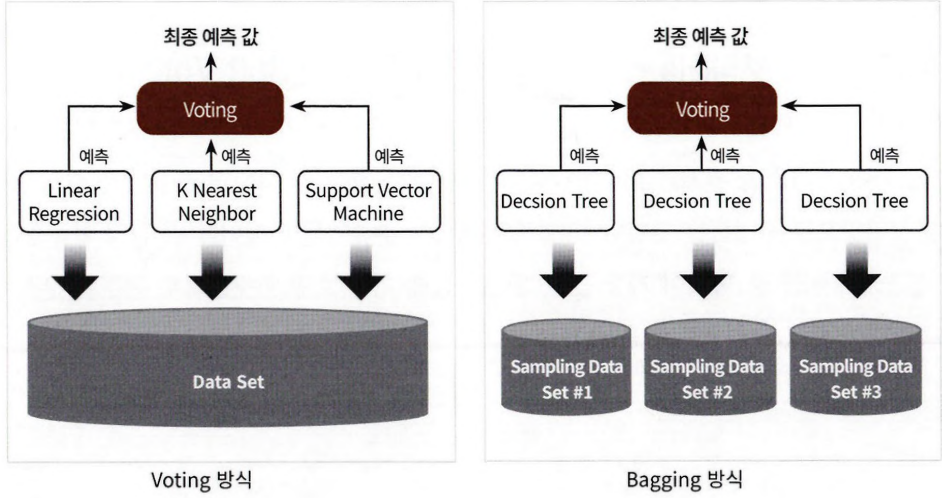

왼쪽 그림 - 보팅 분류기 도식화
- 선형 회귀, K 최근접 이웃, 서포트 벡터 머신이라는 3
개의 ML 알고리즘이 같은 데이터 세트에 대해 학습하고 예측한 결과를 가지고 보팅을 통해 최종 예측
결과를 선정하는 방식

오른쪽 그림 - 배깅 분류기 도식화
- 개별 Classifier에게 데이터를 샘플링해서 추출하는 방식을 부트스트래핑(Bootstrapping) 분할 방식
- 개별 분류기가 부트스트래핑 방식으로 샘플링된 데이터 세트에 대해서 학습을 통해 개별적인 예측을 수행한 결과를 보팅을 통해서 최종 예측 결과를 선정하는 방식이 바로 배깅 앙상블 방식
- 중첩을 허용

부스팅
- 여러 개의 분류기가 순차적으로 학습을 수행하되, 앞에서 학습한 분류기가 예측이 틀린 데이터에 대해서는 올바르게 예측할 수 있도록 다음 분류기에게는 가중치(weight)를 부여하면서 학습과 예측을 진행하는 것
- 대표적인 부스팅 모듈: 그래디언트 부스트, XGBoost(eXtra Gradient Boost), LightGBM(Light Gradient Boost)

스태킹: 여러 가지 다른 모델의 예측 결괏값을 다시 학습 데이터로 만들어서 다른 모델(메타 모델)로 재학습시켜 결과를 예측하는 방법

# 보팅 유형 - 하드 보팅(Hard Voting)과 소프트 보팅(Soft Voting)

하드 보팅
- 다수결 원칙과 비슷
- 예측한 결괏값들 중 다수의 분류기가 결정한 예측값을
최종 보팅 결괏값으로 선정하는 것

소프트 보팅
- 분류기들의 레이블 값 결정 확률을 모두 더하
고 이를 평균해서 이들 중 확률이 가장 높은 레이블 값을 최종 보팅 결괏값으로 선정
  - 일반적으로 소프트 보팅이 보팅 방법으로 적용

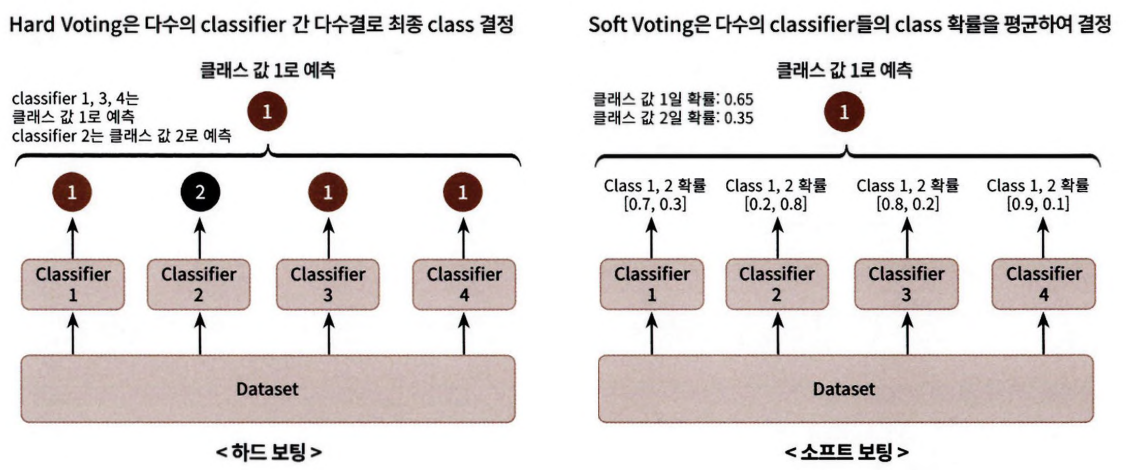

왼쪽) 하드 보팅
- Classifier 1 번, 2번, 3번, 4번인 4개로 구성한 보팅 앙상블 기법에서 분류기 1번, 3번, 4번이 1로 레이블 값을 예측하고 분류기 2번이 2로 레이블 값을 예측하면 다수결 원칙에 따라서 최종 예측은 레이블 값 1이 됨

오른쪽) 소프트 보팅
- 각 분류기의 레이블 값 예측 확률을 평균 내어 최종
결정
- 레이블 값 1의 확률이 0.65로 레이블 값 2인 확률 0.35보다 크므로 레이블 값 1로 최종 보팅하는 것


** 일반적으로 하드 보팅보다는 소프트 보팅이 예측 성능이 좋아서 더 많이 사용

# 보팅 분류기(Voting Classifier)

보팅 방식의 앙상블을 구현한 VotingClassifier 클래스

위스콘신 유방암 데이터 세트를 예측 분석
- 유방암의 악성종양, 양성종양 여부를 결정하는 이진 분류 데이터 세트
- 종양의 크기, 모양 등의 형태와 관련한 많은 피처를 가지고 있음
- load_breast_cancer() 함수를 통해 자체에서 위스콘신 유방암 데이터 세트를 생성


In [6]:
import pandas as pd
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

cancer = load_breast_cancer()

data_df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
data_df.head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


In [7]:
# 개별 모델은 로지스틱 회귀와 KNN임.
lr_clf = LogisticRegression(solver='liblinear')
knn_clf = KNeighborsClassifier(n_neighbors=8)

# 개별 모델을 소프트 보팅 기반의 앙상블 모델로 구현한 분류기
vo_clf = VotingClassifier(estimators=[('LR', lr_clf), ('KNN', knn_clf)], voting='soft')
X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target,
test_size=0.2, random_state= 156)

# VotingClassifier 학습/예측/평가.
vo_clf.fit(X_train, y_train)
pred = vo_clf.predict(X_test)
print('Voting 분류기 정확도: {0:.4f}'.format(accuracy_score(y_test, pred)))

# 개별 모델의 학습/예측/평가.
classifiers = [lr_clf, knn_clf]
for classifier in classifiers:
  classifier.fit(X_train, y_train)
  pred = classifier.predict(X_test)
  class_name= classifier.__class__.__name__
  print('{0} 정확도: {1:.4f}'.format(class_name, accuracy_score(y_test, pred)))

Voting 분류기 정확도: 0.9561
LogisticRegression 정확도: 0.9474
KNeighborsClassifier 정확도: 0.9386


# 랜덤 포레스트


배깅: 같은 알고리즘으로 여러 개의 분류기를 만들어서
보팅으로 최종 결정하는 알고리즘

배깅의 대표적인 알고리즘 = 랜덤 포레스트
- 앙상블 알고리즘 중 비교적 빠른 수행 속도를 가지고 있으며, 다양한 영역에서 높은 예측 성능을 보임


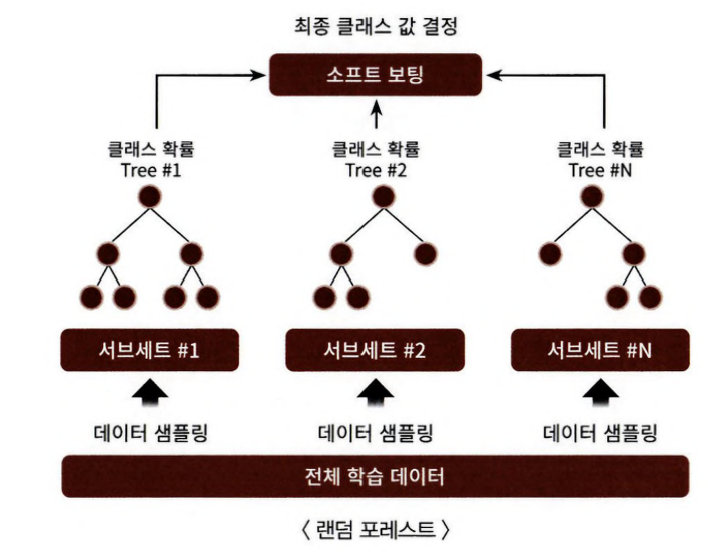

개별적인 분류기의 기반 알고리즘은 결정 트리이지만 개별 트리가 학습하는 데이터 세트는 전체 데이터에서 일부가 중첩되게 샘플링된 데이터 세트

여러 개의 데이터 세트를 중첩되게 분리하는 것을 부트스트래핑(bootstrapping) 분할 방식이라고 함



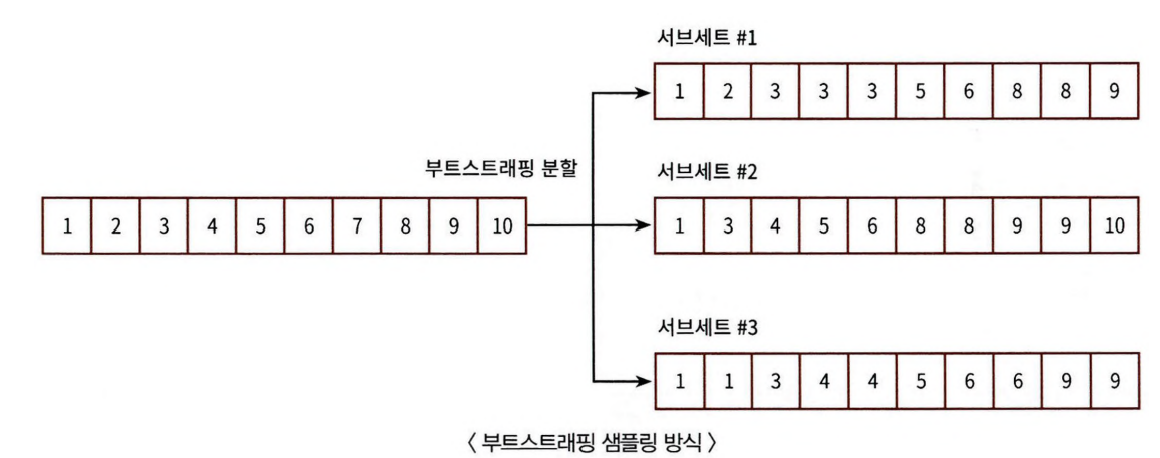

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

def get_new_feature_name_df(old_feature_name_df):
  feature_dup_df=pd.DataFrame(data=old_feature_name_df.groupby('column_name').cumcount(), columns=['dup_cnt'])
  feature_dup_df=feature_dup_df.reset_index()
  new_feature_name_df=pd.merge(old_feature_name_df.reset_index(), feature_dup_df, how='outer')
  new_feature_name_df['column_name']=new_feature_name_df[['column_name','dup_cnt']].apply(lambda x: x[0]+'_'+str(x[1]) if x[1]>0 else x[0], axis=1)
  new_feature_name_df=new_feature_name_df.drop(['index'], axis=1)
  return new_feature_name_df

def get_human_dataset():
  feature_name_df = pd.read_csv('/content/features.txt', sep='\s+',
  header=None, names=['column_index', 'column_name'])
  new_feature_name_df = get_new_feature_name_df(feature_name_df)
  feature_name = new_feature_name_df.iloc[:, 1].values.tolist()
  X_train = pd.read_csv('/content/X_train.txt', sep='\s+', names=feature_name)
  X_test = pd.read_csv('/content/X_test.txt', sep='\s+', names=feature_name)
  y_train = pd.read_csv('/content/y_train.txt', sep='\s+', header=None, names=['action'])
  y_test = pd.read_csv('/content/y_test.txt', sep='\s+', header=None, names=['action'])
  return X_train, X_test, y_train, y_test

# 결정 트리에서 사용한 get_human_dataset( )를 이용해 학습/테스트용 DataFrame 반환
X_train, X_test, y_train, y_test = get_human_dataset()

# 랜덤 포레스트 학습 및 별도의 테스트 세트로 예측 성능 평가
rf_clf = RandomForestClassifier(random_state=0, max_depth=8)
rf_clf.fit(X_train, y_train)
pred = rf_clf.predict(X_test)
accuracy = accuracy_score(y_test, pred)
print( '랜덤 포레스트 정확도: {0:.4f}' .format(accuracy))

랜덤 포레스트 정확도: 0.9220


# 랜덤 포레스트 하이퍼 파라미터 및 튜닝

- n_estimators: 랜덤 포레스트에서 결정 트리의 개수를 지정, 디폴트는 10개, 많이 설정할수록 좋은 성능을
기대할 수 있지만 계속 증가시킨다고 성능이 무조건 향상되는 것은 아니다. 또한 늘릴수록 학습 수행 시간이 오래 걸리는 것도 감안해야 한다.
- max_features는 결정 트리에 사용된 maxjeatures 파라미터와 같다. 하지만 RandomForestClassifier의 기본
max_features는 'None'이 아니라 'auto', 즉 'sqrt'와 같다. 따라서 랜덤 포레스트의 트리를 분할하는 피처를 참조할 때 전체 피처가 아니라 sqrt(전체 피처 개수)만큼 참조한다.
- max_depth나 min_samples_leat, min_samples_split와 같이 결정 트리에서 과적합을 개선하기 위해 사용되는 파라미터가 랜덤 포레스트에도 똑같이 적용될 수 있다.

In [10]:
from sklearn.model_selection import GridSearchCV

params = {
'max_depth':[8, 16, 24],
'min_samples_leaf':[1, 6, 12],
'min_samples_split':[2, 8, 16]
}

# RandomForestClassifier 객체 생성 후 GridSearchCV 수행
rf_clf = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)
grid_cv = GridSearchCV(rf_clf , param_grid=params , cv=2, n_jobs=-1)
grid_cv.fit(X_train , y_train)
print('최적 하이퍼 파라미터:\n', grid_cv.best_params_)
print('최고 예측 정확도: {0:.4f}'.format(grid_cv.best_score_))

최적 하이퍼 파라미터:
 {'max_depth': 16, 'min_samples_leaf': 6, 'min_samples_split': 16}
최고 예측 정확도: 0.9157


In [11]:
rf_clf1 = RandomForestClassifier(n_estimators=100, min_samples_leaf=6, max_depth=16, min_samples_split=2, random_state=0)
rf_clf1.fit(X_train , y_train)
pred = rf_clf1.predict(X_test)
print('예측 정확도: {0:.4f}'.format(accuracy_score(y_test, pred)))

예측 정확도: 0.9253


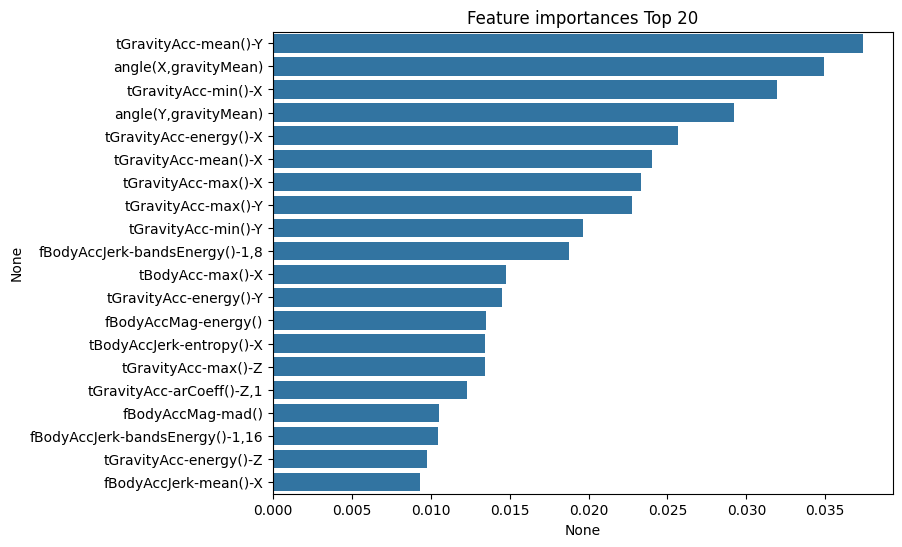

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

ftr_importances_values = rf_clf1.feature_importances_
ftr_importances = pd.Series(ftr_importances_values, index=X_train.columns)
ftr_top20 = ftr_importances.sort_values(ascending=False)[:20]

plt.figure(figsize=(8, 6))
plt.title('Feature importances Top 20')
sns.barplot(x=ftr_top20, y=ftr_top20.index)
plt.show()

# 5. GBM(Gradient Boosting Machine)

부스팅 알고리즘: 여러 개의 약한 학습기(weak learner)를 순차적으로 학습-예측하면서 잘못 예측
한 데이터에 가중치 부여를 통해 오류를 개선해 나가면서 학습하는 방식
- 부스팅의 대표적인 구현 = AdaBoost(Adaptive boosting) & 그래디언트 부스트

에이다 부스트(AdaBoost)
- 오류 데이터에 가중치를 부여하면서 부스팅을 수행하는 대표적인 알고리즘

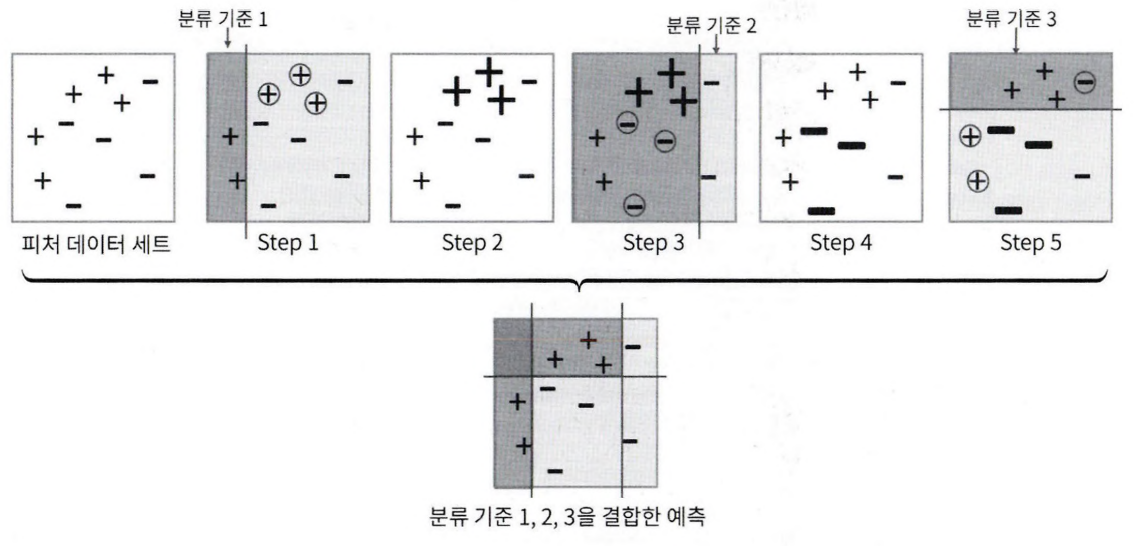

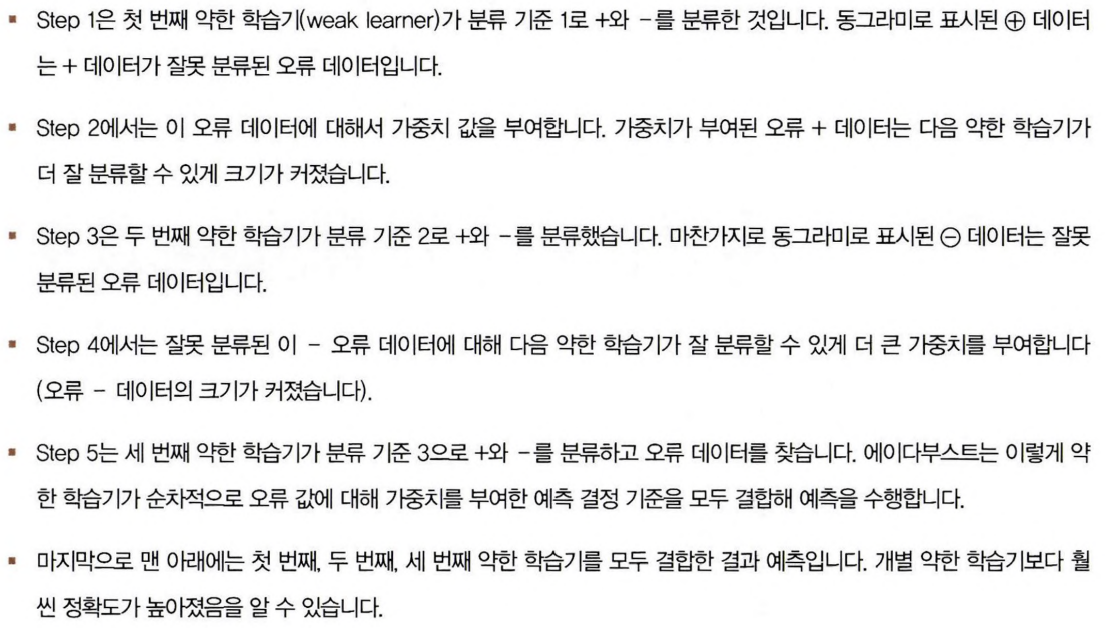

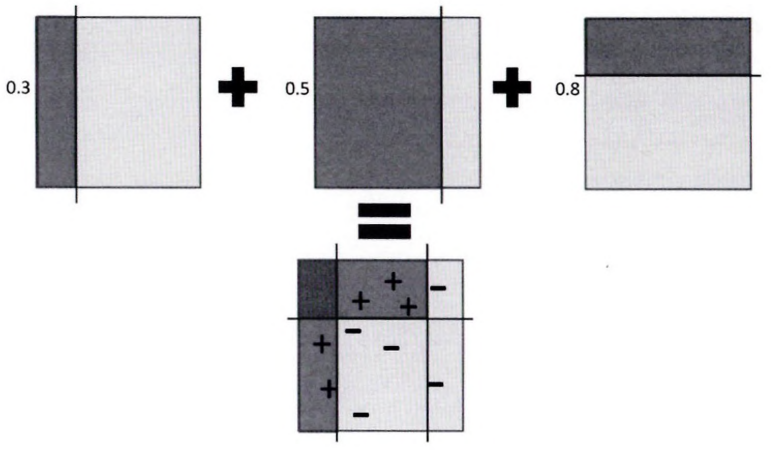

GBM(Gradient Boost Machine)
- 에이다부스트와 유사하나, 가중치 업데이트를 경사 하강법(Gradient Descent)을 이용하는 것이 큰 차이
  - 경사 하강법(Gradient Descent): 최소화하는 방향성을 가지고 반복적으로 가중치 값을 업데이트
- 오류 값 = 실제 값 - 예측값


In [13]:
from sklearn.ensemble import GradientBoostingClassifier
import time
import warnings
warnings.filterwarnings('ignore')
X_train, X_test, y_train, y_test = get_human_dataset()

# GBM 수행 시간 측정을 위함. 시작 시간 설정.
start_time = time.time()

gb_clf = GradientBoostingClassifier(random_state=0)
gb_clf.fit(X_train, y_train)
gb_pred = gb_clf.predict(X_test)
gb_accuracy = accuracy_score(y_test, gb_pred)
print('GBM 정확도: {0:.4f}'.format(gb_accuracy))
print("GBM 수행 시간: {0:.1f} 초 ".format(time.time()-start_time))

GBM 정확도: 0.9379
GBM 수행 시간: 2017.4 초 


# GBM 하이퍼 파라미터 소개

- loss: 경사 하강법에서 사용할 비용 함수를 지정,특별한 이유가 없으면 기본값인 ‘deviance’를 그대로 적용
- learning_rate: GBM이 학습을 진행할 때마다 적용하는 학습률
  - Weak learner가 순차적0 루 오류 값을 보정해 나가는 데 적용하는 계수
  - 0~1 사이의 값을 지정할 수 있으며 기본값은 0.1
- n_estimators: weak learner의 개수
  - 개수가 많을수록 예측 성능이 일정 수준까지는 좋아질 수 있음 <= weak learner가 순차적으로 오류를 보정
  - 개수가 많을수록 수행 시간이 오래 걸림
  - 기본값 : 100개
- subsample: weak learner가 학습에 사용하는 데이터의 샘플링 비율
  - 기본값: 1 = 전체 학습 데이터를
기반으로 학습한다는 의미
  - 과적합이 염려되는 경우 subsample을 1보다 작은 값으로 설정하기


GBM은 과적합에도 강한 뛰어난 예측 성능을 가진 알고리즘이지만 수행 시간이 오래 걸린다는 단점이 있음

# XGBoost(eXtra Gradient Boost)

XGBoost는 GBM에 기반하고 있지만, GBM의 단점인 느린 수행 시간 및 과적합 규제(Regularization) 부재 등의 문제를 해결해서 매우 각광을 받고 있음
- XGBoost는 병렬 CPU 환경에서 병렬 학습이 가능해 기존 GBM보다 빠르게 학습을 완료할 수 있음

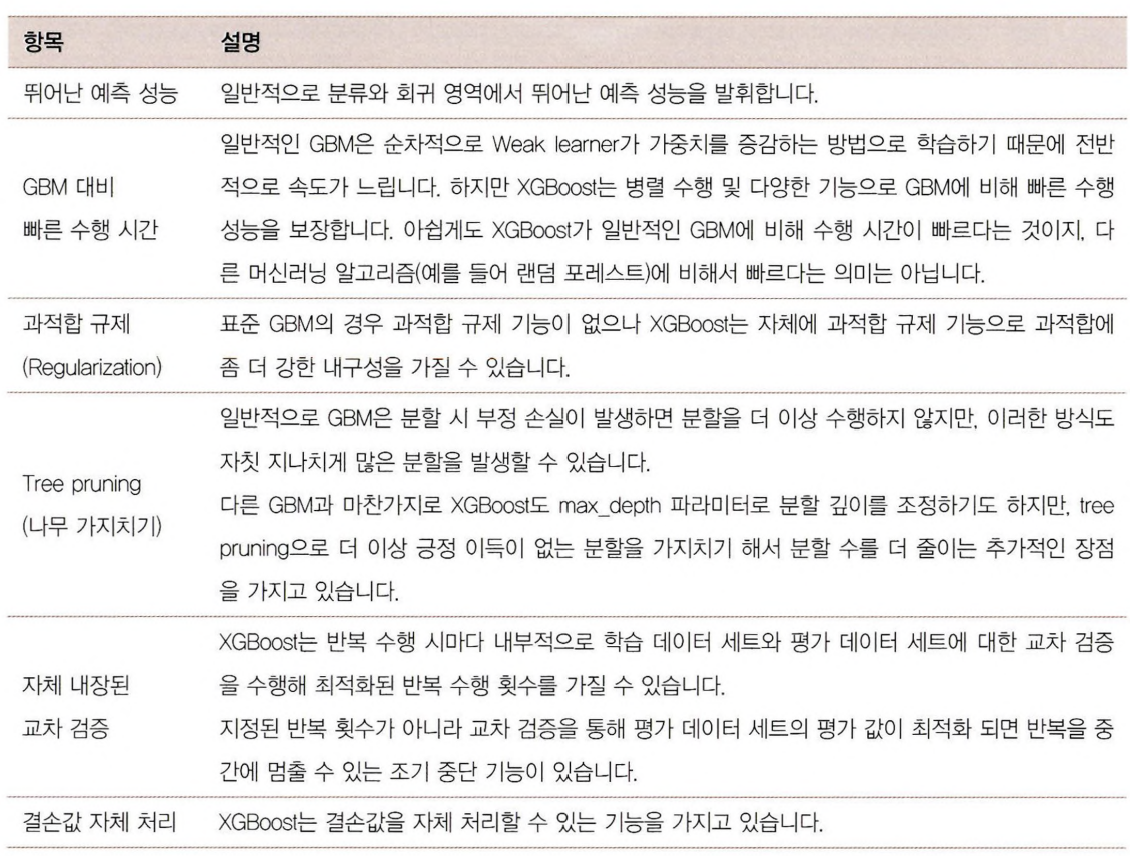

# XGBoost 설치하기

In [14]:
# pip install xgboost=1.5.0

In [15]:
import xgboost as xgb
from xgboost import XGBClassifier

# 파이썬 래퍼 XGBoost 하이퍼 파라미터

XGBoost는 GBM과 유사한 하이퍼 파라미터를
동일하게 가지고 있으며, 여기에 조기 중단(early stopping), 과적합을 규제하기 위한 하이퍼 파라미
터 등이 추가됨
- 파이썬 래퍼 XGBoost 모듈과 사이킷런 래퍼 XGBoost 모듈의 일부 하이퍼 파라미터는 약간 다르므
로 이에 대한 주의가 필요
  - 사이킷런 파라미터의 범용화된 이름 규칙 (Naming Rule) 에 따라 파라미터 명이 달라짐

파이썬 래퍼 XGBoost 하이퍼 파라미터를 유형
- 일반 파라미터: 일반적으로 실행 시 스레드의 개수나 silent 모드 등의 선택을 위한 파라미터로서 디폴트 파라미터 값을 바꾸는 경우는 거의 없음
- 부스터 파라미터: 트리 최적화, 부스팅, regularization 등과 관련 파라미터 등을 지칭
- 학습 태스크 파라미터: 학습 수행 시의 객체 함수, 평가를 위한 지표 등을 설정하는 파라미터

<주요 일반 파라미터>
- booster: gbtree(tree based model) 또는 gblinear(linear model) 선택. 디폴트는 gbtree
- silent; 디폴트는 0이며, 출력 메시지를 나타내고 싶지 않을 경우 1로 설정
- nthread: CPU의 실행 스레드 개수를 조정하며, 디폴트는 CPU의 전체 스레드를 다 사용하는 것, 멀티 코어/스레드 CPU 시스템에서 전체 CPU를 사용하지 않고 일부 CPU만 사용해 ML 애플리케이션을 구동하는 경우에 변경


<주요 부스터 파라미터>
- eta [default=0.3, alias: learning_rate]: GBM의 학습률(learning rate)과 같은 파라미터
  - 0에서 1 사이의 값을
지정하며 부스팅 스텝을 반복적으로 수행할 때 업데이트되는 학습률 값 파이썬 래퍼 기반의 xgboost를 이용할 경우 디폴트는 0.3. 사이킷런 래퍼 클래스를 이용할 경우 eta는 learning_rate 파라미터로 대체되며, 디폴트는 0.1 / 보통 0.01~0.2 사이의 값 선호
- num_boost_rounds: GBM의 n_estimators와 같은 파라미터
-min_child_weight[default네: 트리에서 추가적으로 가지를 나눌지를 결정하기 위해 필요한 데이터들의 weight 총합.
- min_child_weight이 클수록 분할을 자제, 과적합을 조절하기 위해 사용
- gamma [default=0, alias：min_split_loss]: 트리의 리프 누드를 추가적으로 나눌지를 결정할 최소 손실 감소 값
  - 해당 값보다 큰 손실(loss)이 감소된 경우에 리프 노드를 분리, 값이 클수록 과적합 감소 효과가 있음
- max_depth[default=6]: 트리 기반 알고리즘의 max_depth와 같음, 0 지정 시 깊이 제한X / 보통은 3~10 사이의 값을 적용
- sub_sample[default=1]: GBM의 subsample과 동일, 트리가 커져서 과적합되는 것을 제어하기 위해 데이터를 샘플링하는 비율을 지정 / 일반적으로 0.5~1 사이의 값을 사용
- colsample_bytree[default=1]: GBM의 max_features와 유사, 트리 생성에 필요한 피처(칼럼)를 임의로 샘플링하는 데 사용 / 매우 많은 피처가 있는 경우 과적합을 조정하는 데 적용
- lambda [default=1, alias： reg_lambda: L2 Regularization 적용 값, 피처 개수가 많을 경우 적용을 검토하며 값이 클 수록 과적합 감소 효과가 있음
- alpha [default=0, alias： reg_alpha]: L1 Regularization 적용 값, 피처 개수가 많을 경우 적용을 검토하며 값이 클수록 과적합 감소 효과가 있음
- scale_pos_weight [defaults]: 특정 값으로 치우친 비대칭한 클래스로 구성된 데이터 세트의 균형을 유지하기 위한 파라미터

<학습 태스크 파라미터>
- objective: 최솟값을 가져야 할 손실 함수를 정의, XGBoost는 많은 유형의 손실함수를 사용할 수 있음
- binary:logistic: 이진 분류일 때 적용
- multi:softmax: 다중 분류일 때 적용, 손실함수가 multi:softmax일 경우에는 레이블 클래스의 개수인 num_class 파라미터를 지정해야 함
- multi:softprob: multi:softmax와 유사하나 개별 레이블 클래스의 해당하는 예측 확률을 반환
- eval_metric; 검증에 사용되는 함수를 정의, 기본값은 회귀인 경우는 rmse, 분류일 경우에는 error
  - rmse: Root Mean Square Error
  - mae: Mean Absolute Error
  - logloss: Negative log-likelihood
  - error: Binary classification error rate
  - merror: Multiclass logloss
  - auc: Area under the curve

In [16]:
import xgboost

print(xgboost.__version__)

3.4.1


# 파이썬 래퍼 XGBoost 적용 - 위스콘신 유방암 예측

In [17]:
import xgboost as xgb
from xgboost import plot_importance
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

dataset = load_breast_cancer()
features= dataset.data
labels = dataset.target

cancer_df = pd.DataFrame(data=features, columns=dataset.feature_names)
cancer_df['target']= labels
cancer_df.head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


In [18]:
print(dataset.target_names)
print(cancer_df['target'].value_counts())

['malignant' 'benign']
target
1    357
0    212
Name: count, dtype: int64


위스콘신 유방암 데이터 세트의 80%를 학습용으로, 20%를 테스트용으로 추출한 뒤 이 80%의 학습용
데이터에서 90%를 최종 학습용, 10%를 검증용으로
분할
- 검증용 데이터 세트를 별
도로 분할하는 이유:  XGBoost가 제공하는 기능인 검증 성능 평가와 조기 중단(early stopping)을
수행해 보기 위함

In [20]:
# cancer_df에서 feature용 DataFrame과 Label용 Series 객체 추출
# 맨 마지막 칼럼이 Label임. Feature용 DataFrame은 cancer_df의 첫번째 칼럼에서 맨 마지막 두번째 칼럼까지를 :-1 슬라이싱으로 추출.
X_features = cancer_df.iloc[:, :-1]
y_label = cancer_df.iloc[:, -1]

# 전체 데이터 중 80%는 학습용 데이터, 20%는 테스트용 데이터 추출
X_train, X_test, y_train, y_test=train_test_split(X_features, y_label, test_size=0.2, random_state=156)

# 위에서 만든 X.train, y_train을 다시 쪼개서 90%는 학습과 10%는 검증용 데이터로 분리
X_tr, X_val, y_tr, y_val= train_test_split(X_train, y_train, test_size=0.1, random_state=156 )
print(X_train.shape, X_test.shape)
print(X_tr.shape, X_val.shape)


(455, 30) (114, 30)
(409, 30) (46, 30)


** DataFrame 기반의 학습 데이터 세트와
테스트 데이터 세트를 DMatrix로 변환하는 예제

In [22]:
# 만약 구버전 XGBoost에서 DataFrame으로 DMatrix 생성이 안 될 경우 X_train.values로 넘파이 변환.
# 학습, 검증, 테스트용 DMatrix를 생성.
dtr=xgb.DMatrix(data=X_tr, label=y_tr)
dval=xgb.DMatrix(data=X_val, label=y_val)
dtest=xgb.DMatrix(data=X_test, label=y_test)

- max_depth(트리 최대 깊이)는 3.
- 학습률 eta는 0.1(XGBCIassifier를 사용할 경우 eta가 아니라 learning_rate)
- 예제 데이터가 0 또는 1 이진 분류이므로 목적함수(objective)는 이진 로지스틱(binarylogistic)
- 오류 함수의 평가 성능 지표는 logloss
- num_rounds(부스팅 반복 횟수)는 400회

In [23]:
params = { 'max.depth':3, 'eta': 0.05, 'objective':'binary:logistic', 'eval_metric':'logloss'}
num_rounds = 400

In [24]:
# 학습 데이터 셋은 'train' 또는 평가 데이터 셋은 'eval' 로 명기합니다.
eval_list = [(dtr,'train'),(dval,'eval')] # 또는 eval_list = [(dval/eval')] 만 명기해도 무방

# 하이퍼 파라미터와 early stopping 파라미터를 train( ) 함수의 파라미터로 전달
xgb_model = xgb.train(params = params , dtrain=dtr , num_boost_round=num_rounds , \
early_stopping_rounds=50, evals=eval_list )


[0]	train-logloss:0.62387	eval-logloss:0.62838
[1]	train-logloss:0.58495	eval-logloss:0.60050
[2]	train-logloss:0.54966	eval-logloss:0.57614
[3]	train-logloss:0.51751	eval-logloss:0.55407
[4]	train-logloss:0.48808	eval-logloss:0.53310
[5]	train-logloss:0.46083	eval-logloss:0.51153
[6]	train-logloss:0.43570	eval-logloss:0.49302
[7]	train-logloss:0.41251	eval-logloss:0.47600
[8]	train-logloss:0.39106	eval-logloss:0.46076
[9]	train-logloss:0.37117	eval-logloss:0.44654
[10]	train-logloss:0.35195	eval-logloss:0.43265
[11]	train-logloss:0.33466	eval-logloss:0.42021
[12]	train-logloss:0.31853	eval-logloss:0.40903
[13]	train-logloss:0.30332	eval-logloss:0.39880
[14]	train-logloss:0.28925	eval-logloss:0.38921
[15]	train-logloss:0.27578	eval-logloss:0.38006
[16]	train-logloss:0.26285	eval-logloss:0.37089
[17]	train-logloss:0.25108	eval-logloss:0.36393
[18]	train-logloss:0.23992	eval-logloss:0.35722
[19]	train-logloss:0.22913	eval-logloss:0.34970
[20]	train-logloss:0.21898	eval-logloss:0.34270
[2

In [28]:
pred_probs = xgb_model.predict(dtest)
print('predict( ) 수행 결괏값을 10개만 표시, 예측 확률 값으로 표시됨')
print(np.round(pred_probs[:10], 3))

# 예측 확률이 0.5보다 크면 1 , 그렇지 않으면 0으로 예측값 결정하여 List 객체인 preds에 저장
preds = [ 1 if x > 0.5 else 0 for x in pred_probs]
print('예측값 10개만 표시:', preds[:10])

predict( ) 수행 결괏값을 10개만 표시, 예측 확률 값으로 표시됨
[0.96  0.006 0.62  0.186 0.979 0.999 0.998 0.997 0.997 0.002]
예측값 10개만 표시: [1, 0, 1, 0, 1, 1, 1, 1, 1, 0]


In [36]:
# 1. 필요한 라이브러리/함수 import (추가된 부분)
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 2. 평가 함수 정의
def get_clf_eval(y_test, pred, pred_proba):
    confusion = confusion_matrix(y_test, pred)
    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    roc_auc = roc_auc_score(y_test, pred_proba)

    print('오차행렬')
    print(confusion)
    print('정확도:{0:.4f}, 정밀도:{1:.4f}, 재현율:{2:.4f}, F1:{3:.4f}, AUC:{4:.4f}'.format(
        accuracy, precision, recall, f1, roc_auc
    ))

# 3. 함수 호출
# (이전에 예측한 변수명이 preds, pred_probs 라면 아래처럼 호출)
get_clf_eval(y_test, preds, pred_probs)

오차행렬
[[34  3]
 [ 2 75]]
정확도:0.9561, 정밀도:0.9615, 재현율:0.9740, F1:0.9677, AUC:0.9926


<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

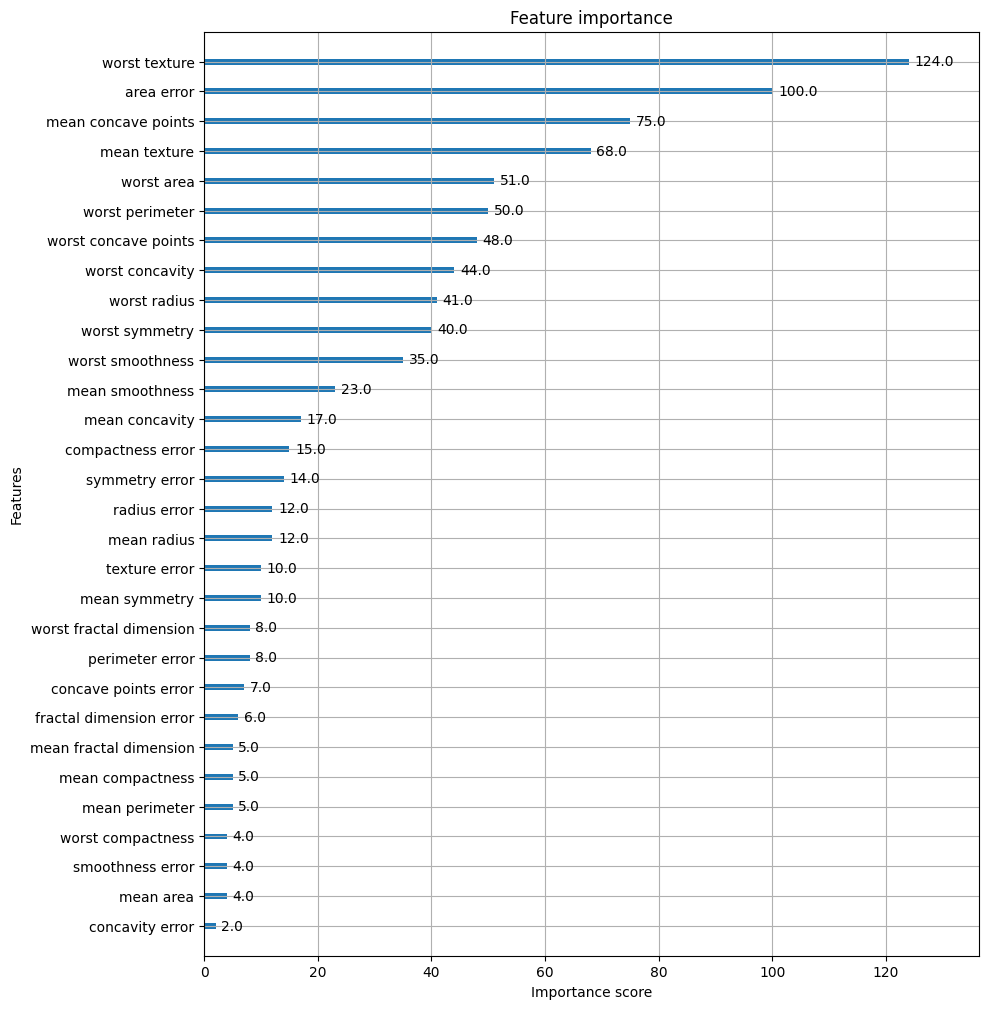

In [37]:
import matplotlib.pyplot as plt
%matplotlib inline
fig, ax = plt.subplots(figsize=(10, 12))
plot_importance(xgb_model, ax=ax)

# 사이킷런 래퍼 XGBoost의 개요 및 적용

In [39]:
# 사이킷런 래퍼 XGBoost 클래스인 XGBClassifier 임포트
from xgboost import XGBClassifier

# Warning 메시지를 없애기 위해 eval.metric 값을 XGBClassifier 생성 인자로 입력.
xgb_wrapper = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=3, eval_metric='logloss')
xgb_wrapper.fit(X_train, y_train, verbose=True)
w_preds=xgb_wrapper.predict(X_test)
w_pred_proba = xgb_wrapper.predict_proba(X_test)[:, 1]

In [40]:
get_clf_eval(y_test , w_preds, w_pred_proba)

오차행렬
[[35  2]
 [ 1 76]]
정확도:0.9737, 정밀도:0.9744, 재현율:0.9870, F1:0.9806, AUC:0.9958


In [43]:
from xgboost import XGBClassifier

# early_stopping_rounds와 eval_metric을 XGBClassifier 생성자에 지정
xgb_wrapper = XGBClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=3,
    early_stopping_rounds=50,
    eval_metric="logloss"
)

evals = [(X_tr, y_tr), (X_val, y_val)]

# fit()에는 eval_set과 verbose만 전달
xgb_wrapper.fit(X_tr, y_tr, eval_set=evals, verbose=True)

ws50_preds = xgb_wrapper.predict(X_test)
ws50_pred_proba = xgb_wrapper.predict_proba(X_test)[:, 1]

[0]	validation_0-logloss:0.62473	validation_1-logloss:0.63225
[1]	validation_0-logloss:0.58662	validation_1-logloss:0.60730
[2]	validation_0-logloss:0.55210	validation_1-logloss:0.58562
[3]	validation_0-logloss:0.52058	validation_1-logloss:0.56615
[4]	validation_0-logloss:0.49155	validation_1-logloss:0.54542
[5]	validation_0-logloss:0.46491	validation_1-logloss:0.53043
[6]	validation_0-logloss:0.43969	validation_1-logloss:0.51101
[7]	validation_0-logloss:0.41648	validation_1-logloss:0.49373
[8]	validation_0-logloss:0.39503	validation_1-logloss:0.47735
[9]	validation_0-logloss:0.37517	validation_1-logloss:0.46266
[10]	validation_0-logloss:0.35673	validation_1-logloss:0.44940
[11]	validation_0-logloss:0.33938	validation_1-logloss:0.43843
[12]	validation_0-logloss:0.32276	validation_1-logloss:0.42597
[13]	validation_0-logloss:0.30774	validation_1-logloss:0.41552
[14]	validation_0-logloss:0.29356	validation_1-logloss:0.40645
[15]	validation_0-logloss:0.27989	validation_1-logloss:0.39635
[1

In [44]:
get_clf_eval(y_test , ws50_preds, ws50_pred_proba)

오차행렬
[[35  2]
 [ 2 75]]
정확도:0.9649, 정밀도:0.9740, 재현율:0.9740, F1:0.9740, AUC:0.9947


In [46]:
# early_stopping_ro니nds를 10으로 설정하고 재학습
xgb_wrapper=XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=3, early_stopping_rounds=10, eval_metric='logloss')

xgb_wrapper.fit(X_tr,y_tr, eval_set=evals, verbose=True)

ws10_preds=xgb_wrapper.predict(X_test)
ws10_preds_proba=xgb_wrapper.predict_proba(X_test)[:,1]
get_clf_eval(y_test, ws10_preds, ws10_preds_proba)

[0]	validation_0-logloss:0.62473	validation_1-logloss:0.63225
[1]	validation_0-logloss:0.58662	validation_1-logloss:0.60730
[2]	validation_0-logloss:0.55210	validation_1-logloss:0.58562
[3]	validation_0-logloss:0.52058	validation_1-logloss:0.56615
[4]	validation_0-logloss:0.49155	validation_1-logloss:0.54542
[5]	validation_0-logloss:0.46491	validation_1-logloss:0.53043
[6]	validation_0-logloss:0.43969	validation_1-logloss:0.51101
[7]	validation_0-logloss:0.41648	validation_1-logloss:0.49373
[8]	validation_0-logloss:0.39503	validation_1-logloss:0.47735
[9]	validation_0-logloss:0.37517	validation_1-logloss:0.46266
[10]	validation_0-logloss:0.35673	validation_1-logloss:0.44940
[11]	validation_0-logloss:0.33938	validation_1-logloss:0.43843
[12]	validation_0-logloss:0.32276	validation_1-logloss:0.42597
[13]	validation_0-logloss:0.30774	validation_1-logloss:0.41552
[14]	validation_0-logloss:0.29356	validation_1-logloss:0.40645
[15]	validation_0-logloss:0.27989	validation_1-logloss:0.39635
[1

<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

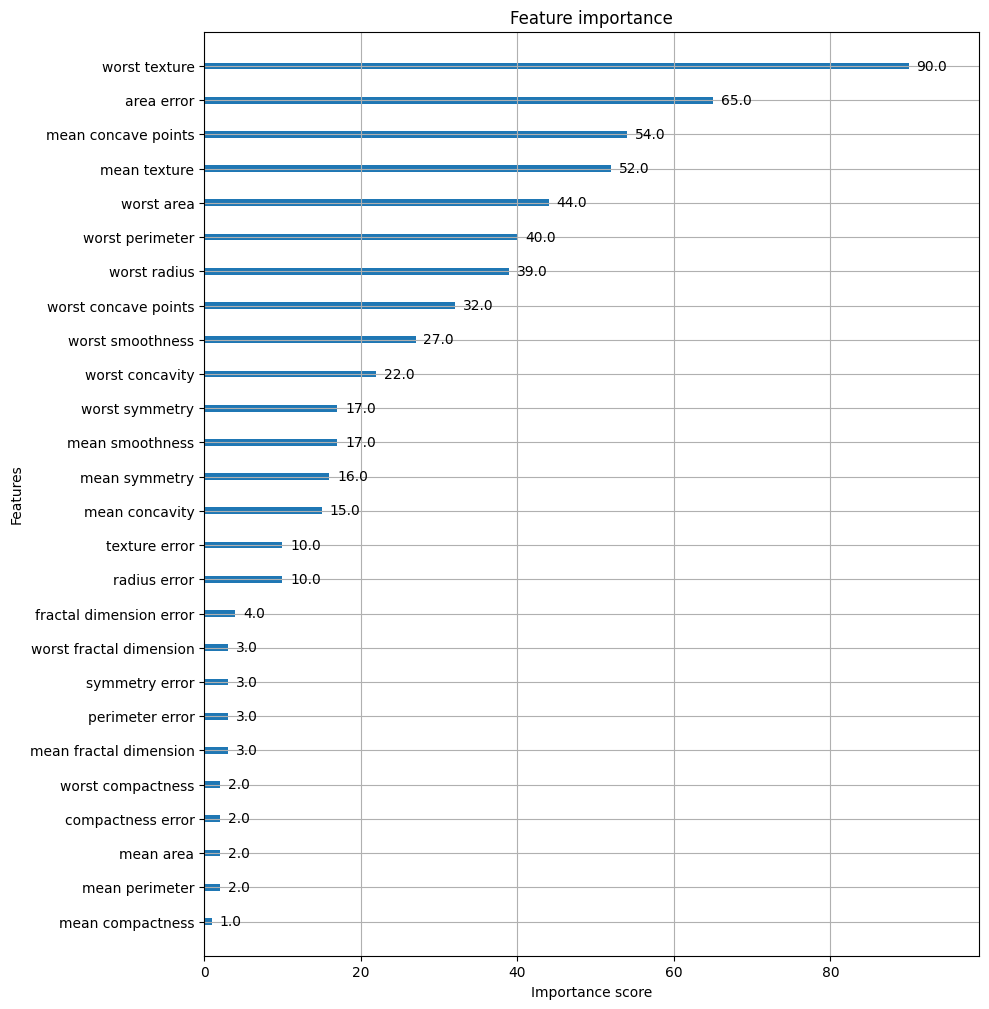

In [47]:
from xgboost import plot_importance
import matplotlib.pyplot as plt
%matplotlib inline

fig, ax = plt.subplots(figsize=(10, 12))
# 사이킷런 래퍼 클래스를 입력해도 무방.
plot_importance(xgb_wrapper, ax=ax)